In [2]:
# Đọc dữ liệu
import pandas as pd

df = pd.read_csv("../data/IMDB Dataset.csv")

print(df.shape)
print(df.head())
print(df.columns)

(50000, 2)
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
Index(['review', 'sentiment'], dtype='str')


In [3]:
# Kiểm tra phân phối nhãn
print(df["sentiment"].value_counts())

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [4]:
# Kiểm tra dữ liệu thiếu
print(df.isnull().sum())

review       0
sentiment    0
dtype: int64


In [5]:
# Kiểm tra đánh giá trùng lặp
print("Số dòng trùng lặp:", df.duplicated().sum())

Số dòng trùng lặp: 418


In [6]:
# Kiểm tra độ dài bài đánh giá
df["review_length"] = df["review"].str.len()

print(df["review_length"].describe())

count    50000.000000
mean      1309.431020
std        989.728014
min         32.000000
25%        699.000000
50%        970.000000
75%       1590.250000
max      13704.000000
Name: review_length, dtype: float64


In [7]:
# Kiểm tra nhãn và văn bản trùng lặp
print("Số review trùng nội dung:",
      df["review"].duplicated().sum())

Số review trùng nội dung: 418


In [8]:
# Kiểm tra nhãn của dữ liệu trùng
print(df["sentiment"].value_counts())
print(df["sentiment"].unique())

sentiment
positive    25000
negative    25000
Name: count, dtype: int64
<StringArray>
['positive', 'negative']
Length: 2, dtype: str


In [9]:
# Chia dữ liệu thành Train và phần còn lại
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["sentiment"]
)

print("Train:", train_df.shape)
print("Phần còn lại:", temp_df.shape)

Train: (35000, 3)
Phần còn lại: (15000, 3)


In [10]:
# Chia dữ liệu còn lại (temp_df) thành Validation và test
val_df,test_df = train_test_split(
    temp_df,
    test_size = 0.5,
    random_state = 42,
    stratify = temp_df["sentiment"]
)
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (35000, 3)
Validation: (7500, 3)
Test: (7500, 3)


In [11]:

print("TRAIN:")
print(train_df["sentiment"].value_counts(normalize=True))

print("\nVALIDATION:")
print(val_df["sentiment"].value_counts(normalize=True))

print("\nTEST:")
print(test_df["sentiment"].value_counts(normalize=True))


TRAIN:
sentiment
positive    0.5
negative    0.5
Name: proportion, dtype: float64

VALIDATION:
sentiment
negative    0.5
positive    0.5
Name: proportion, dtype: float64

TEST:
sentiment
negative    0.5
positive    0.5
Name: proportion, dtype: float64


In [12]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()


In [13]:

X_train = train_df["review"]
y_train = train_df["sentiment"]


In [14]:
print(X_train.shape)
print(y_train.shape)

(35000,)
(35000,)


In [15]:

tfidf.fit(X_train)


,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",'word'
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",None
,"token_pattern token_pattern: str, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp selects tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",'(?u)\\b\\w\\w+\\b'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1

In [16]:

print("Số từ trong vocabulary:", len(tfidf.vocabulary_))


Số từ trong vocabulary: 87391


In [17]:

X_train_tfidf = tfidf.transform(X_train)

print("Kích thước ma trận:", X_train_tfidf.shape)


Kích thước ma trận: (35000, 87391)


In [18]:

print(type(X_train_tfidf))
print("Số phần tử khác 0:", X_train_tfidf.nnz)


<class 'scipy.sparse._csr.csr_matrix'>
Số phần tử khác 0: 4764222


In [19]:

X_val = val_df["review"]

X_val_tfidf = tfidf.transform(X_val)

print("Kích thước Validation:", X_val_tfidf.shape)


Kích thước Validation: (7500, 87391)


In [20]:

X_test = test_df["review"]

X_test_tfidf = tfidf.transform(X_test)

print("Kích thước Test:", X_test_tfidf.shape)


Kích thước Test: (7500, 87391)


In [21]:

y_val = val_df["sentiment"]
y_test = test_df["sentiment"]

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)


y_train: (35000,)
y_val: (7500,)
y_test: (7500,)


In [22]:
from sklearn.linear_model import LogisticRegression

In [23]:
model = LogisticRegression()

In [24]:
model.fit(X_train_tfidf, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [25]:
y_val_pred = model.predict(X_val_tfidf)

In [26]:
print(y_val_pred.shape)

(7500,)


In [27]:
from sklearn.metrics import accuracy_score, classification_report

In [28]:
val_accuracy = accuracy_score(y_val, y_val_pred)
print("Validation Accuracy:", val_accuracy)

Validation Accuracy: 0.8902666666666667


In [29]:
print(classification_report(y_val, y_val_pred))

              precision    recall  f1-score   support

    negative       0.90      0.88      0.89      3750
    positive       0.89      0.90      0.89      3750

    accuracy                           0.89      7500
   macro avg       0.89      0.89      0.89      7500
weighted avg       0.89      0.89      0.89      7500



In [30]:

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=["negative", "positive"]
)

print(cm)


[[3316  434]
 [ 389 3361]]


In [31]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt


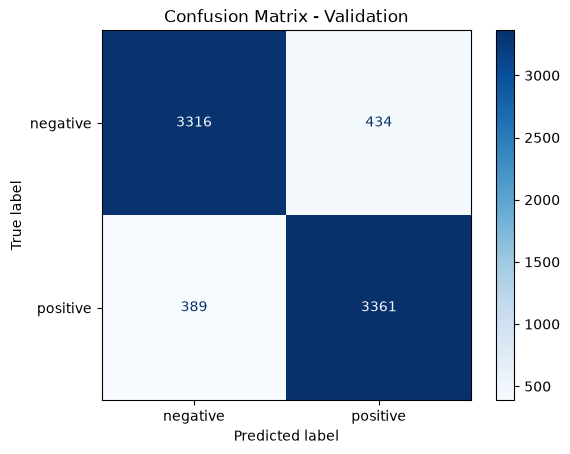

In [36]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    labels=["negative", "positive"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Validation")
plt.show()

In [38]:

import pandas as pd

error_df = pd.DataFrame({
    "review": val_df["review"].values,
    "true_label": y_val.values,
    "predicted_label": y_val_pred
})


error_df = error_df[
    error_df["true_label"] != error_df["predicted_label"]
]

print("Số mẫu dự đoán sai:", len(error_df))
print(error_df[["true_label", "predicted_label"]].head())


Số mẫu dự đoán sai: 823
   true_label predicted_label
18   positive        negative
47   negative        positive
62   negative        positive
76   negative        positive
80   positive        negative


In [39]:
pd.set_option("display.max_colwidth", 300)

print(
    error_df[
        ["review", "true_label", "predicted_label"]
    ].head(3).to_string(index=False)
)

In [40]:
all_predictions_df = pd.DataFrame({
    "review": val_df["review"].values,
    "true_label": y_val.values,
    "predicted_label": y_val_pred
})

correct_df = all_predictions_df[
    all_predictions_df["true_label"] == all_predictions_df["predicted_label"]
].copy()

error_df = all_predictions_df[
    all_predictions_df["true_label"] != all_predictions_df["predicted_label"]
].copy()

print("Số mẫu dự đoán đúng:", len(correct_df))
print("Số mẫu dự đoán sai:", len(error_df))

Số mẫu dự đoán đúng: 6677
Số mẫu dự đoán sai: 823


In [41]:
pd.set_option("display.max_colwidth", 300)

print(
    correct_df[
        ["review", "true_label", "predicted_label"]
    ].head(3).to_string(index=False)
)

In [42]:
print("=== 5 mẫu dự đoán sai ===")
print(
    error_df[
        ["review", "true_label", "predicted_label"]
    ].iloc[3:8].to_string(index=False)
)

print("\n=== 5 mẫu dự đoán đúng ===")
print(
    correct_df[
        ["review", "true_label", "predicted_label"]
    ].iloc[3:8].to_string(index=False)
)

=== 5 mẫu dự đoán sai ===
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              